# 4. El Chocó en el tiempo: 2018 a hoy

El IPM municipal es una foto de 2018. Para ver **qué pasó después** se usa la serie departamental que el
DANE calcula cada año con la Encuesta Nacional de Calidad de Vida (ECV). No llega a municipios, pero sí
muestra si la brecha del Chocó con el país se cierra o no.

In [1]:
# Preparación: ubica la carpeta del repo y carga el paquete del estudio
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
for _ in range(5):
    if (RAIZ / "src" / "pobreza").exists():
        break
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pobreza import datos, ipm
from pobreza.config import ETIQUETAS, IPM_INDICADORES, DIMENSIONES, PACIFICO, REPORTES
from pobreza.graficos import CHOCO, RESTO, ACENTO, NEUTRO, DIMENSION_COLORES, estilo, guardar, fuente

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.max_columns", 40)

In [2]:
dep = datos.ipm_departamental()
# La serie nacional empieza en 2010, pero la departamental en 2018: se compara desde 2018.
dep = dep[dep["anio"] >= 2018]
anios = sorted(dep["anio"].unique())
print(f"Serie {anios[0]}–{anios[-1]}; indicadores: {sorted(dep['indicador'].unique())}")

def serie(indicador, dominio="total"):
    s = dep[(dep.indicador == indicador) & (dep.dominio == dominio)]
    return s.pivot_table(index="anio", columns="departamento", values="valor")

ipm_t = serie("ipm")

Serie 2018–2025; indicadores: ['analfabetismo', 'bajo_logro_educativo', 'barreras_acceso_salud', 'barreras_primera_infancia', 'desempleo_larga_duracion', 'empleo_informal', 'hacinamiento_critico', 'inasistencia_escolar', 'intensidad', 'ipm', 'm0', 'paredes_inadecuadas', 'pisos_inadecuados', 'rezago_escolar', 'sin_acueducto', 'sin_alcantarillado', 'sin_aseguramiento_salud', 'trabajo_infantil']


## 4.1 Incidencia del IPM: el Chocó frente al país y los demás departamentos

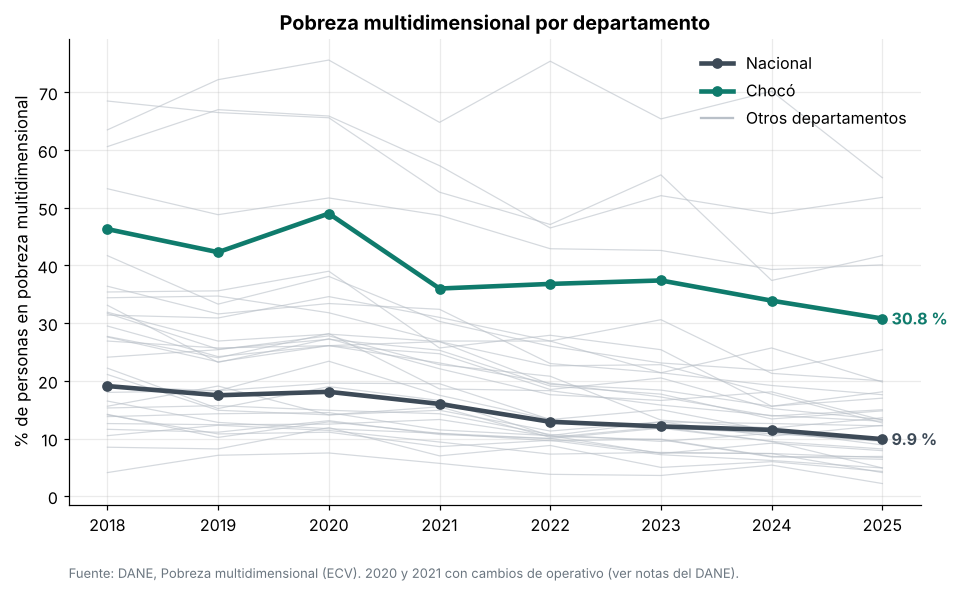

,Chocó,Nacional,Brecha (pp),Razón,Puesto del Chocó (1 = más pobre)
anio,,,,,
2018,46.3,19.1,27.2,2.4,5.0
2019,42.3,17.5,24.8,2.4,5.0
2020,49.0,18.1,30.9,2.7,5.0
2021,36.0,16.0,20.0,2.2,5.0
2022,36.8,12.9,23.9,2.9,5.0
2023,37.4,12.1,25.3,3.1,5.0
2024,33.9,11.5,22.4,3.0,5.0
2025,30.8,9.9,20.9,3.1,5.0


In [3]:
fig, ax = plt.subplots(figsize=(10, 5.5))
otros = [c for c in ipm_t.columns if c not in ("Chocó", "Nacional")]
for c in otros:
    ax.plot(ipm_t.index, ipm_t[c], color=RESTO, lw=0.8, alpha=0.6)
for c, color, nombre in (("Nacional", NEUTRO, "Nacional"), ("Chocó", CHOCO, "Chocó")):
    if c in ipm_t:
        ax.plot(ipm_t.index, ipm_t[c], color=color, lw=3, marker="o", label=nombre)
        ax.annotate(f"{ipm_t[c].iloc[-1]:.1f} %", (ipm_t.index[-1], ipm_t[c].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", color=color, va="center", fontweight="bold")
ax.plot([], [], color=RESTO, label="Otros departamentos")
ax.set(ylabel="% de personas en pobreza multidimensional", xticks=ipm_t.index,
       title="Pobreza multidimensional por departamento")
ax.legend()
fuente(ax, "DANE, Pobreza multidimensional (ECV). 2020 y 2021 con cambios de operativo (ver notas del DANE).")
guardar(fig, "04_serie_departamental")
plt.show()

if {"Chocó", "Nacional"} <= set(ipm_t.columns):
    tabla = pd.DataFrame({"Chocó": ipm_t["Chocó"], "Nacional": ipm_t["Nacional"]})
    tabla["Brecha (pp)"] = tabla["Chocó"] - tabla["Nacional"]
    tabla["Razón"] = tabla["Chocó"] / tabla["Nacional"]
    tabla["Puesto del Chocó (1 = más pobre)"] = ipm_t.drop(columns="Nacional").rank(axis=1, ascending=False)["Chocó"]
    display(tabla.round(2))

## 4.2 Cabecera y zona rural en el tiempo

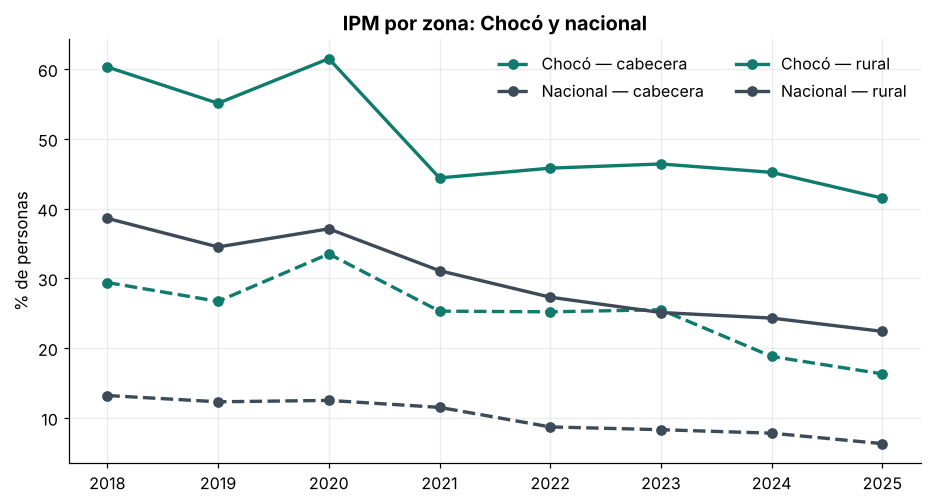

In [4]:
filas = []
for dom in ("cabecera", "rural"):
    s = serie("ipm", dom)
    for c in ("Chocó", "Nacional"):
        if c in s:
            filas.append(s[c].rename(f"{'Chocó' if c == 'Chocó' else c} — {dom}"))
if filas:
    dom_t = pd.concat(filas, axis=1)
    fig, ax = plt.subplots(figsize=(10, 5))
    estilos = {"cabecera": "--", "rural": "-"}
    for col in dom_t:
        lugar, dom = col.split(" — ")
        ax.plot(dom_t.index, dom_t[col], ls=estilos[dom], marker="o", lw=2.2,
                color=CHOCO if lugar == "Chocó" else NEUTRO, label=col)
    ax.set(ylabel="% de personas", xticks=dom_t.index, title="IPM por zona: Chocó y nacional")
    ax.legend(ncol=2)
    guardar(fig, "04_serie_zonas")
    plt.show()

## 4.3 Cada indicador: ¿dónde mejoró y dónde no?

Cambio entre el primer y el último año de la serie, en puntos porcentuales.

,Chocó 2018,Chocó 2025,Cambio Chocó (pp),Nacional 2025,Cambio nacional (pp)
indicador,,,,,
Bajo logro educativo,64.4,51.6,-12.8,36.8,-7.7
Sin aseguramiento en salud,13.0,2.1,-10.9,4.7,-6.3
Rezago escolar,37.3,27.7,-9.6,19.7,-7.7
Analfabetismo,27.7,19.0,-8.7,6.4,-3.6
Eliminación inadecuada de excretas,71.3,62.9,-8.4,9.2,-2.4
Barreras primera infancia,12.3,4.9,-7.4,5.3,-3.0
Sin fuente de agua mejorada,68.0,60.9,-7.1,8.3,-3.4
Pisos inadecuados,4.9,2.0,-2.9,4.6,-1.6
Inasistencia escolar,5.7,4.1,-1.6,1.8,-1.3


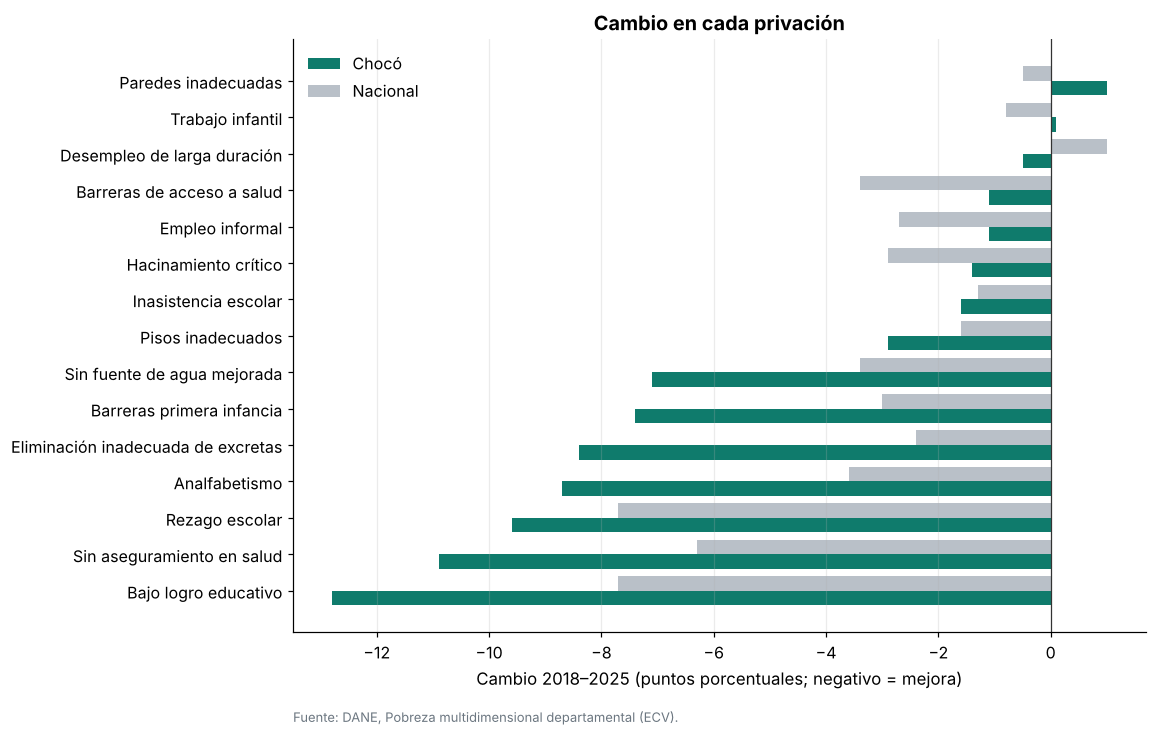

In [5]:
ind_dep = [i for i in IPM_INDICADORES if i in set(dep["indicador"])] + \
          [i for i in ("desempleo_larga_duracion",) if i in set(dep["indicador"])]
filas = []
for i in ind_dep:
    s = serie(i)
    if {"Chocó", "Nacional"} <= set(s.columns):
        filas.append({"indicador": ETIQUETAS.get(i, "Desempleo de larga duración"),
                      f"Chocó {anios[0]}": s["Chocó"].iloc[0], f"Chocó {anios[-1]}": s["Chocó"].iloc[-1],
                      "Cambio Chocó (pp)": s["Chocó"].iloc[-1] - s["Chocó"].iloc[0],
                      f"Nacional {anios[-1]}": s["Nacional"].iloc[-1],
                      "Cambio nacional (pp)": s["Nacional"].iloc[-1] - s["Nacional"].iloc[0]})
cambios = pd.DataFrame(filas).set_index("indicador").sort_values("Cambio Chocó (pp)")
display(cambios.round(1))

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(cambios))
ax.barh(y - 0.2, cambios["Cambio Chocó (pp)"], height=0.4, color=CHOCO, label="Chocó")
ax.barh(y + 0.2, cambios["Cambio nacional (pp)"], height=0.4, color=RESTO, label="Nacional")
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(y, cambios.index)
ax.set(xlabel=f"Cambio {anios[0]}–{anios[-1]} (puntos porcentuales; negativo = mejora)",
       title="Cambio en cada privación")
ax.legend()
ax.grid(axis="y", visible=False)
fuente(ax, "DANE, Pobreza multidimensional departamental (ECV).")
guardar(fig, "04_cambio_indicadores")
plt.show()

## 4.4 Incidencia (H), intensidad (A) e IPM ajustado (M0)

- **H**: cuántas personas son pobres.
- **A**: entre los pobres, qué proporción de las privaciones ponderadas sufren en promedio.
- **M0 = H × A**: combina las dos. Si A baja, la pobreza es menos profunda aunque H no cambie.

In [6]:
partes = {}
for clave, nombre in (("ipm", "H (incidencia, %)"), ("intensidad", "A (intensidad, %)"), ("m0", "M0 × 100")):
    s = serie(clave) * (100 if clave == "m0" else 1)
    if "Chocó" in s:
        partes[nombre + " — Chocó"] = s["Chocó"]
    if "Nacional" in s:
        partes[nombre + " — Nacional"] = s["Nacional"]
if partes:
    display(pd.DataFrame(partes).round(1))

,"H (incidencia, %) — Chocó","H (incidencia, %) — Nacional","A (intensidad, %) — Chocó","A (intensidad, %) — Nacional",M0 × 100 — Chocó,M0 × 100 — Nacional
anio,,,,,,
2018,46.3,19.1,44.3,41.7,20.5,8.0
2019,42.3,17.5,44.1,41.4,18.7,7.2
2020,49.0,18.1,44.5,41.4,21.8,7.5
2021,36.0,16.0,43.7,40.8,15.7,6.5
2022,36.8,12.9,43.7,40.3,16.1,5.2
2023,37.4,12.1,43.1,40.1,16.1,4.9
2024,33.9,11.5,42.8,40.2,14.5,4.6
2025,30.8,9.9,43.9,40.4,13.5,4.0


## 4.5 Lo que dice la foto municipal de 2018 sobre el total departamental

Con la población de cada municipio se puede reconstruir un IPM departamental con datos del censo y
compararlo con el de la ECV para 2018. Si se parecen, las dos fuentes cuentan la misma historia.

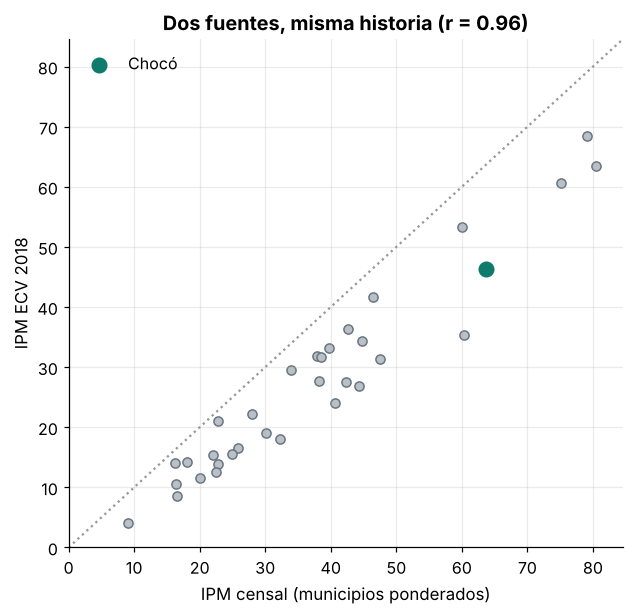

In [7]:
base = datos.base_municipal()
if "poblacion_total" in base:
    censal = (base.assign(p=base.ipm * base.poblacion_total).groupby("cod_dpto")[["p", "poblacion_total"]].sum())
    censal = (censal["p"] / censal["poblacion_total"]).rename("IPM censal 2018")
    ecv = dep[(dep.indicador == "ipm") & (dep.dominio == "total") & (dep.anio == anios[0])].set_index("cod_dpto")["valor"]
    comp = pd.concat([censal, ecv.rename(f"IPM ECV {anios[0]}")], axis=1).dropna()
    r = comp.corr().iloc[0, 1]
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.scatter(comp.iloc[:, 0], comp.iloc[:, 1], color=RESTO, edgecolor="#6b7680")
    if "27" in comp.index:
        ax.scatter(*comp.loc["27"], color=CHOCO, s=90, zorder=3, label="Chocó")
    lim = [0, max(comp.max()) * 1.05]
    ax.plot(lim, lim, color="#999", ls=":")
    ax.set(xlabel="IPM censal (municipios ponderados)", ylabel=f"IPM ECV {anios[0]}", xlim=lim, ylim=lim,
           title=f"Dos fuentes, misma historia (r = {r:.2f})")
    ax.legend()
    guardar(fig, "04_censo_vs_ecv")
    plt.show()

## Para llevar

- La serie departamental dice si el Chocó **converge** con el país: si la brecha en puntos baja pero la razón
  (Chocó ÷ nacional) sube, el Chocó mejora más despacio en términos relativos.
- Mirar los indicadores uno por uno muestra qué avances son del país entero (por ejemplo, aseguramiento en
  salud) y cuáles el Chocó no ha logrado mover.
- Las cifras de 2020 y 2021 tienen cambios en la forma de recolección por la pandemia: conviene no sacar
  conclusiones fuertes de un solo año.